# Thin layers, arrested shapes and finite-time stopping

Mudflows, fresh concrete spreading on a slab, a drop of gel on a table and a paint film on a wall are all **thin layers** of a yield-stress fluid. Two questions dominate their engineering: how fast does a shallow layer flow, and what shape does it leave when it stops? The first is answered by a depth-integrated flux law that follows from the Herschel–Bulkley (HB) law with a linear stress profile across the layer; the second by a static inequality that admits many arrested shapes, so that a final deposit fixes the yield stress only under additional assumptions. This notebook derives the thin-layer flux (Eq. (28) of the review), checks it against its Newtonian limit and against direct integration, uses the shallow-layer shape to reproduce the slump-flow estimate of a concrete yield stress (Supplementary Note S15, Example 2) and its sensitivity (Note S11 B), introduces the plastocapillary and Bond numbers that govern spreading drops, and ends with a numerical illustration of why finite-time stopping does not by itself prove that a yield stress exists (Note S16).

## Where this is in the review

* **Sec. VII E** *Thin layers, arrested shapes and stopping* — stress $G(h-z)$ in a layer, yielded basal thickness $a=(h-\sigma_y/G)_+$, depth-integrated flux **Eq. (28)** and its Newtonian limit $Gh^3/(3\mu)$, mass conservation $\partial_t h+\nabla\cdot\boldsymbol q=0$, the pseudo-plug of Balmforth and Craster (1999), the static condition $\rho g h|\nabla h|\le\sigma_y$ and the non-uniqueness of arrested shapes, and finite-time cessation.
* **Sec. IX E** *Pipes and free-surface channels* — uniform flow down an inclined channel as a parameter-free test of Eq. (28) (Chambon, Ghemmour and Naaim, 2014): kaolin predicted, Carbopol requiring $\sigma_y$ and $K$ 10–20 % above the rheometer values. **Sec. IX F** *Spreading and imbibition* — the plastocapillary number $J=\sigma_y R/\Gamma$ and the Bond number $\mathrm{Bo}=\Delta\rho gR^2/\Gamma$; **Table XIII** (free-surface flow and spreading: what a shear calibration supports).
* **Supplementary Note S15 B, Example 2** — yield stress of a self-compacting concrete from a slump-flow test, $\sigma_y=225\rho gV^2/(128\pi^2R^5)$ (Roussel and Coussot, 2005): 23 Pa at $R=350$ mm, 50 Pa at 300 mm.
* **Supplementary Note S11 B**, **Eqs. (S26)–(S27)** — sensitivity of that estimate, $\mathrm d\sigma_y/\sigma_y=\mathrm d\rho/\rho+2\,\mathrm dV/V-5\,\mathrm dR/R$; **Note S11 A, Table SV** — the analytical checks "Newtonian thin layer", "Thin layer with yield" and "Spreading coefficient" implemented in `scripts/verify_equations.py`.
* **Supplementary Note S16** — the conditional finite-time cessation bound, **Eqs. (S36)–(S38)**: the yield-stress term and the power-law term with $n<1$ each produce extinction in finite time.
* This topic has no figure of its own in the article; the checks below are against a live run of `scripts/verify_equations.py` (Table SV).

## Learning objectives

1. Derive the stress distribution and the velocity profile in a thin layer with a no-slip base and a stress-free surface, and obtain the depth-integrated flux, Eq. (28).
2. Verify Eq. (28) against its Newtonian and power-law limits and against a double quadrature of the velocity profile.
3. Use Eq. (28) for uniform flow down an incline and see how sensitive the flow height is to the HB parameters.
4. Derive the marginal shallow-layer shape from $\rho gh|\nabla h|=\sigma_y$, obtain the slump-flow coefficient $C=225/(128\pi^2)$, reproduce the worked concrete example and propagate its measurement uncertainty.
5. Explain why an arrested shape satisfies an inequality and therefore constrains $\sigma_y$ only with additional assumptions; define $J$ and $\mathrm{Bo}$.
6. Show numerically that a shear-thinning power-law fluid also stops in finite time, so that finite arrest is not evidence of $\sigma_y>0$.

## 1. Theory

### 1.1 Stress and velocity in a thin layer

Consider a layer of depth $h$ on a no-slip base $z=0$ with a stress-free surface $z=h$, driven along $x$ by a uniform force per unit volume of magnitude $G$ (for a layer on an incline of angle $\theta$, $G=\rho g\sin\theta$; for a horizontal layer with a surface slope, $G=\rho g|\partial_x h|$ in the lubrication approximation). A force balance on the slab between $z$ and the free surface gives the shear stress

$$
\sigma(z)=G\,(h-z),
$$

which is largest at the base and vanishes at the surface. Exactly as in the pipe, the material yields only where $\sigma>\sigma_y$, i.e. in a **basal layer** of thickness

$$
a=\left(h-\frac{\sigma_y}{G}\right)_+ ,
$$

while the upper part $a<z<h$ moves as a plug at the velocity of the top of the sheared layer. Nothing flows unless $Gh>\sigma_y$. In the sheared layer $\sigma-\sigma_y=G(a-z)$, so the HB law gives $\dot\gamma=\mathrm du/\mathrm dz=[G(a-z)/K]^{1/n}$ and, with $u(0)=0$,

$$
u(z)=\left(\frac{G}{K}\right)^{1/n}\frac{a^{1+1/n}-(a-z)^{1+1/n}}{1+1/n},\qquad 0\le z\le a,
\qquad u=u(a)\ \text{for } a\le z\le h .
$$

### 1.2 Depth-integrated flux, Eq. (28)

Integrating over the depth, $q=\int_0^a u\,\mathrm dz+(h-a)\,u(a)$, gives Eq. (28) of the review,

$$
q=\left(\frac{G}{K}\right)^{1/n}\left[\frac{a^{2+1/n}}{2+1/n}+\frac{(h-a)\,a^{1+1/n}}{1+1/n}\right],
$$

taken with the sign of the driving force. The first term is the flux of the sheared layer, the second the flux carried by the plug. For $\sigma_y=0$ the whole depth is sheared ($a=h$) and the second term vanishes; for $n=1$ as well, $q=Gh^3/(3\mu)$, the Newtonian film. Mass conservation, $\partial_t h+\nabla\cdot\boldsymbol q=0$, then closes a reduced evolution equation for $h(x,t)$. Where depth and plug speed vary along the layer, the "plug" is strictly a weakly deforming **pseudo-plug** (Balmforth and Craster, 1999): a rigid region cannot stretch, so the upper layer is held just at the yield stress and deforms slowly — the leading-order flux of Eq. (28) is unaffected. Depth-averaged HB models of this kind are widely used for mudflows and fine-grained geophysical flows (Coussot, 1997; Ancey, 2007).

### 1.3 Arrested shapes and the slump-flow estimate

When the forcing is gravity acting on a layer of variable depth on a horizontal substrate, $G=\rho g|\nabla h|$, and the layer is static wherever the basal stress is below the yield stress,

$$
\rho g h\,|\nabla h|\le\sigma_y .
$$

This is an **inequality**, so it admits many arrested shapes; which one is realized depends on the initial shape, the forcing history and the contact line. A final deposit therefore constrains $\sigma_y$ only under additional assumptions and cannot determine all three parameters (Pashias et al., 1996; Roussel and Coussot, 2005): the static shape carries no rate information, so $K$ and $n$ can only be obtained from the transient (Note S15).

The usual additional assumption is that the flow stopped **marginally**: the stress fell to exactly $\sigma_y$ everywhere, so that the inequality is an equality. For an axisymmetric deposit this gives $h\,\mathrm dh/\mathrm dr=-\sigma_y/(\rho g)$, i.e.

$$
h(r)^2=\frac{2\sigma_y}{\rho g}\,(R-r),
\qquad
V=\int_0^R 2\pi r\,h(r)\,\mathrm dr=\frac{8\pi}{15}\sqrt{\frac{2\sigma_y}{\rho g}}\,R^{5/2},
$$

and solving for the yield stress gives the spreading-regime relation of Roussel and Coussot (2005), Eq. (S26) of the review,

$$
\sigma_y=C\,\frac{\rho gV^2}{R^5},\qquad C=\frac{225}{128\pi^2}\approx0.178 .
$$

It holds when the final thickness is small compared with the radius (the shallow-spread regime of a slump-flow test), and it is independent of $K$ and $n$. Logarithmic differentiation gives Eq. (S27),

$$
\frac{\mathrm d\sigma_y}{\sigma_y}=\frac{\mathrm d\rho}{\rho}+2\frac{\mathrm dV}{V}-5\frac{\mathrm dR}{R},
$$

so for independent small random errors the relative variance of $\sigma_y$ is the density variance plus four times the volume variance plus twenty-five times the radius variance; a systematic radius bias must be propagated as a bias.

### 1.4 Capillarity: the plastocapillary and Bond numbers

For a small drop, surface tension $\Gamma$ competes with the yield stress and with gravity. Sec. IX F uses the plastocapillary number and the Bond number,

$$
J=\frac{\sigma_y R}{\Gamma},\qquad \mathrm{Bo}=\frac{\Delta\rho\,gR^2}{\Gamma},
$$

with $R$ a drop radius. Their ratio $J/\mathrm{Bo}=\sigma_y/(\Delta\rho gR)$ compares the yield stress with the hydrostatic stress and is the same group that governs the gravity-driven arrest of Sec. 1.3. An arrested drop again satisfies an inequality with many solutions.

### 1.5 Finite-time cessation

After the forcing is removed, the kinetic energy $E=\rho\|\boldsymbol u\|_2^2/2$ of an HB fluid in a bounded domain with no-slip walls obeys Eq. (S36),

$$
\frac{\mathrm dE}{\mathrm dt}=-\int_\Omega\sigma_y\dot\gamma\,\mathrm dV-\int_\Omega K\dot\gamma^{\,n+1}\,\mathrm dV ,
$$

and each term alone bounds the decay. Under the hypotheses of Note S16 — the yield-stress bound uses the embedding of fields of bounded deformation (Temam and Strang, 1980), which holds in two dimensions; three dimensions need additional hypotheses — the yield-stress term gives $\mathrm dE/\mathrm dt\le-(\sigma_y/C)\sqrt{2E/\rho}$ (Eq. (S37)), so $\sqrt E$ reaches zero within a finite time; but the power-law term gives $\mathrm dE/\mathrm dt\le-cKE^{(n+1)/2}$ (Eq. (S38); valid in two dimensions, and in three for $n+1\ge6/5$), which for $0<n<1$ also extinguishes $E$ in finite time, whereas for $n=1$ the decay is exponential and for $n>1$ algebraic. **A finite stopping time observed in a transient is therefore not, by itself, evidence of a nonzero yield stress** (Huilgol, Mena and Piau, 2002; Chatzimina et al., 2005). Sec. 6 illustrates this with two simple one-dimensional models.

## 2. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq

# Locate the repository root whether the notebook is run from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not write __pycache__ files into scripts/

from hbstyle import C   # the article's colour palette and plot style (we never call hbstyle.save)
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

import verify_equations                        # the review's own regression checks (Note S11 A, Table SV)
g = 9.81                                       # m/s^2, as in the supplementary examples

data folder found: True


## 3. The thin-layer flux

### 3.1 Coding Sec. 1.1 and Eq. (28)

The functions below take the driving gradient $G$, the depth $h$ and the HB triplet in any consistent units.

In [2]:
def yielded_thickness(G, h, ty):
    """a = (h - sigma_y / G)_+ : thickness of the sheared basal layer."""
    return max(h - ty / G, 0.0)

def layer_shear_rate(z, G, h, ty, K, n):
    """Local shear rate du/dz at height z (zero in the plug)."""
    a = yielded_thickness(G, h, ty)
    return (G * np.clip(a - np.asarray(z, float), 0.0, None) / K) ** (1.0 / n)

def layer_velocity(z, G, h, ty, K, n):
    """Velocity profile of Sec. 1.1: sheared for z < a, plug velocity u(a) above."""
    a = yielded_thickness(G, h, ty)
    zz = np.clip(np.asarray(z, float), 0.0, a)
    return (G / K) ** (1 / n) * (a ** (1 + 1 / n) - (a - zz) ** (1 + 1 / n)) / (1 + 1 / n)

def thin_flux(G, h, ty, K, n):
    """Depth-integrated flux per unit width, Eq. (28)."""
    a = yielded_thickness(G, h, ty)
    return (G / K) ** (1 / n) * (a ** (2 + 1 / n) / (2 + 1 / n) + (h - a) * a ** (1 + 1 / n) / (1 + 1 / n))

### 3.2 Checks: limits, double quadrature and the review's own implementation

Table SV lists two checks for Eq. (28): the Newtonian film limit $q=Gh^3/(3\mu)$ (which exposes a confusion between yielded and plug thickness) and equality with a double quadrature of the basal profile (which exposes errors in the plug-flux term and the exponents). We run both, add the power-law limit $q=\dfrac{n}{2n+1}\left(\dfrac{G}{K}\right)^{1/n}h^{2+1/n}$ (a known result for a power-law film, not printed in the review), and compare with `verify_equations.thin_q`.

In [3]:
# Newtonian film
G, h, mu = 3.0, 0.3, 2.0
assert np.isclose(thin_flux(G, h, 0.0, mu, 1.0), G * h**3 / (3 * mu), rtol=1e-12)

# power-law film (a = h): q = n/(2n+1) (G/K)^(1/n) h^(2+1/n)
for n in [0.4, 0.7, 1.3]:
    assert np.isclose(thin_flux(G, h, 0.0, 0.9, n), n / (2 * n + 1) * (G / 0.9) ** (1 / n) * h ** (2 + 1 / n), rtol=1e-12)

# double quadrature: u(z) = int_0^z gdot dz', q = int_0^a u dz + (h - a) u(a)
worst_quad = worst_script = 0.0
for n in [0.4, 0.7, 1.0, 1.3]:
    for ty in [0.0, 0.2, 0.6]:
        G, h, K = 2.0, 0.5, 0.9
        a = yielded_thickness(G, h, ty)
        u_num = lambda z: quad(lambda s: layer_shear_rate(s, G, h, ty, K, n), 0, min(z, a), epsabs=1e-13)[0]
        q_num = quad(u_num, 0, a, epsabs=1e-13)[0] + (h - a) * u_num(a)
        worst_quad = max(worst_quad, abs(thin_flux(G, h, ty, K, n) / q_num - 1))
        worst_script = max(worst_script, abs(thin_flux(G, h, ty, K, n) / verify_equations.thin_q(G, h, ty, K, n) - 1))
        # the closed-form profile of Sec. 1.1 against the integrated shear rate, at a few heights
        for z in [0.1 * a, 0.5 * a, a, h]:
            assert np.isclose(layer_velocity(z, G, h, ty, K, n), u_num(z), rtol=1e-9, atol=1e-14)
print(f"Eq. (28) vs double quadrature of the basal profile: largest relative difference = {worst_quad:.1e}")
print(f"Eq. (28) vs scripts/verify_equations.thin_q:         largest relative difference = {worst_script:.1e}")
assert worst_quad < 1e-7 and worst_script < 1e-12
print("Newtonian film, power-law film and 12 yield cases: all passed.")

Eq. (28) vs double quadrature of the basal profile: largest relative difference = 8.8e-12
Eq. (28) vs scripts/verify_equations.thin_q:         largest relative difference = 0.0e+00
Newtonian film, power-law film and 12 yield cases: all passed.


### 3.3 Profiles across the layer and the onset of flow

We now look at what the formulas describe. The left panel shows velocity profiles for several values of $\sigma_y/(Gh)$, the fraction of the depth that is held below the yield stress (dimensionless units $G=h=K=1$, $n=0.5$). The right panel shows the flux against the driving gradient: nothing flows below $G_c=\sigma_y/h$, and just above it the flux grows as $(G-G_c)^{1+1/n}$ because only a thin basal layer yields. (This onset exponent is the same as for the pipe and the channel, Sec. VII C of the review; the thin-layer case is our own extension of that argument.)

n = 0.5: slope d log q / d log(G - G_c) = 2.999 near onset (1 + 1/n = 3.0), 2.001 far above (1/n = 2.0)
n = 1.0: slope d log q / d log(G - G_c) = 1.998 near onset (1 + 1/n = 2.0), 1.001 far above (1/n = 1.0)


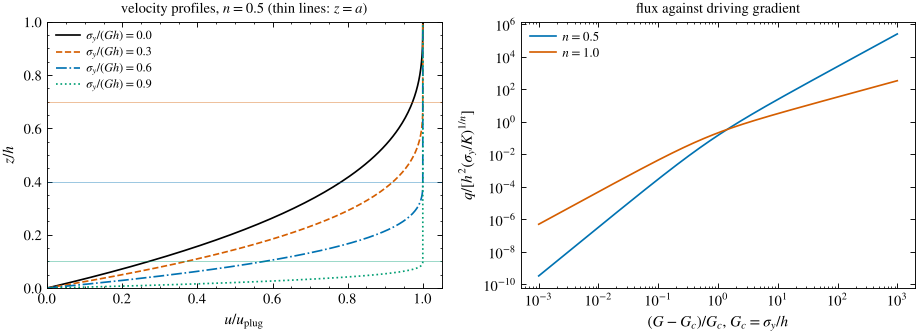

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.3))
z = np.linspace(0, 1, 201)
n = 0.5
for frac, col, ls in zip([0.0, 0.3, 0.6, 0.9], [C["black"], C["red"], C["blue"], C["green"]], ["-", "--", "-.", ":"]):
    u = layer_velocity(z, 1.0, 1.0, frac, 1.0, n)
    ax1.plot(u / u.max(), z, color=col, ls=ls, label=rf"$\sigma_y/(Gh)={frac}$")
    ax1.axhline(1 - frac, color=col, lw=0.5, alpha=0.5)
ax1.set(xlabel=r"$u/u_{\rm plug}$", ylabel=r"$z/h$", xlim=(0, 1.05), ylim=(0, 1),
        title="velocity profiles, $n=0.5$ (thin lines: $z=a$)")
ax1.legend(fontsize=8)

ty, h, K = 1.0, 1.0, 1.0
Gc = ty / h
Gs = Gc * np.logspace(-3, 3, 400) + Gc                  # G - G_c from 1e-3 to 1e3 (times G_c)
for n, col in zip([0.5, 1.0], [C["blue"], C["red"]]):
    q = np.array([thin_flux(G, h, ty, K, n) for G in Gs])
    ax2.loglog((Gs - Gc) / Gc, q, color=col, label=f"$n={n}$")
    slope = np.gradient(np.log(q), np.log(Gs - Gc))
    print(f"n = {n}: slope d log q / d log(G - G_c) = {slope[5]:.3f} near onset (1 + 1/n = {1 + 1/n:.1f}), "
          f"{slope[-5]:.3f} far above (1/n = {1/n:.1f})")
ax2.set(xlabel=r"$(G-G_c)/G_c$, $G_c=\sigma_y/h$", ylabel=r"$q/[h^2(\sigma_y/K)^{1/n}]$", title="flux against driving gradient")
ax2.legend(fontsize=8.5)
for a in (ax1, ax2): a.title.set_fontsize(9.5)
fig.tight_layout()
plt.show()

With $\sigma_y/(Gh)=0.9$ only the bottom 10 % of the layer is sheared and the rest rides on it as a plug; the flux is then tiny. Far above onset the flux grows as $G^{1/n}$, like a power-law film.

### 3.4 Uniform flow down an incline (Sec. IX E) — an illustrative calculation

Steady uniform flow down an inclined channel is a parameter-free test of Eq. (28): gravity alone sets $G=\rho g\sin\theta$, and the flow height for a given discharge follows from the inverse of Eq. (28). Chambon, Ghemmour and Naaim (2014) found that kaolin suspensions followed the prediction from independently measured parameters, whereas Carbopol gels needed $\sigma_y$ and $K$ 10–20 % above the rheometer values to match the measured heights. The numbers below are **illustrative** (they are not the parameters of that study): we take a kaolin-like triplet and ask how much the predicted height changes when $\sigma_y$ and $K$ are raised by 10 % and 20 %.

In [5]:
rho, theta_deg = 1300.0, 15.0                    # kg/m^3, degrees (illustrative)
ty, K, n = 30.0, 10.0, 0.4                       # Pa, Pa s^n, - (illustrative kaolin-like triplet)
q_target = 2.0e-3                                # m^2/s, discharge per unit width
G = rho * g * np.sin(np.radians(theta_deg))      # Pa/m

def height_for_flux(q, G, ty, K, n):
    """Invert Eq. (28) for h at a given discharge per unit width (q increases monotonically with h)."""
    h_c = ty / G                                 # below this depth nothing flows
    return brentq(lambda hh: thin_flux(G, hh, ty, K, n) - q, h_c * (1 + 1e-12), 10.0, xtol=1e-12)

h0 = height_for_flux(q_target, G, ty, K, n)
print(f"G = rho g sin(theta) = {G:.0f} Pa/m; minimum depth for flow h_c = sigma_y/G = {1000 * ty / G:.1f} mm")
print(f"predicted flow height for q = {q_target * 1e3:.1f} x 10^-3 m^2/s: h = {1000 * h0:.1f} mm, "
      f"of which the sheared basal layer is a = {1000 * yielded_thickness(G, h0, ty):.1f} mm")
print("surface velocity (plug) u_s =", f"{layer_velocity(h0, G, h0, ty, K, n):.3f} m/s")
for f in [1.1, 1.2]:
    h_sy = height_for_flux(q_target, G, f * ty, K, n)
    h_K = height_for_flux(q_target, G, ty, f * K, n)
    h_both = height_for_flux(q_target, G, f * ty, f * K, n)
    print(f"+{100 * (f - 1):.0f} % in sigma_y: h {100 * (h_sy / h0 - 1):+.1f} %;  +{100 * (f - 1):.0f} % in K: h {100 * (h_K / h0 - 1):+.1f} %;"
          f"  both: h {100 * (h_both / h0 - 1):+.1f} %")

G = rho g sin(theta) = 3301 Pa/m; minimum depth for flow h_c = sigma_y/G = 9.1 mm
predicted flow height for q = 2.0 x 10^-3 m^2/s: h = 21.1 mm, of which the sheared basal layer is a = 12.0 mm
surface velocity (plug) u_s = 0.108 m/s
+10 % in sigma_y: h +3.6 %;  +10 % in K: h +3.5 %;  both: h +7.1 %
+20 % in sigma_y: h +7.3 %;  +20 % in K: h +6.8 %;  both: h +14.0 %


For this example a 10–20 % change in $\sigma_y$ and $K$ moves the predicted height by 3–14 % (14 % when both are raised by 20 %): a height measurement of per-cent precision can distinguish the rheometer triplet from a triplet 10–20 % stronger, which is why the Carbopol discrepancy reported in Sec. IX E is resolvable. The split between the sheared layer ($a\approx12$ mm) and the plug ($h-a=\sigma_y/G\approx9$ mm, over 40 % of the depth) shows why the yield stress matters so much here.

## 4. Arrested shapes

### 4.1 The marginal shape and the coefficient $C=225/(128\pi^2)$

We verify the volume integral of Sec. 1.3 by quadrature, as `scripts/verify_equations.py` does (Table SV, "Spreading coefficient"), and then show that the inequality $\rho gh|h'|\le\sigma_y$ admits a whole family of arrested shapes with the **same volume and the same yield stress**: scaling the marginal profile of radius $R$ to $h=\alpha\,h_{\rm marg}(r;R')$ with $R'=R\alpha^{-2/5}$ keeps the volume and multiplies $\rho gh|h'|$ by $\alpha^2\le1$, so every member satisfies the static condition.

volume of the marginal shape by quadrature: 5.500000e-03 m^3 (target 5.500000e-03);  C = 0.17810


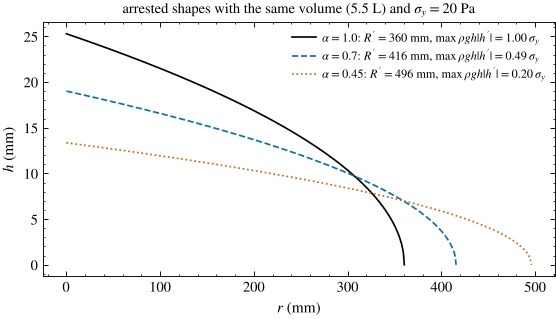

In [6]:
rho_c, V_c, sy_c = 2300.0, 5.5e-3, 20.0           # kg/m^3, m^3, Pa (any values would do for the check)
R_c = (225 / (128 * np.pi**2) * rho_c * g * V_c**2 / sy_c) ** 0.2
h_marg = lambda r, R, sy: np.sqrt(np.clip(2 * sy * (R - r) / (rho_c * g), 0, None))
V_quad = quad(lambda r: 2 * np.pi * r * h_marg(r, R_c, sy_c), 0, R_c, epsabs=1e-14)[0]
print(f"volume of the marginal shape by quadrature: {V_quad:.6e} m^3 (target {V_c:.6e});  C = {225 / (128 * np.pi**2):.5f}")
assert np.isclose(V_quad, V_c, rtol=1e-8)
assert np.isclose(sy_c, 225 / (128 * np.pi**2) * rho_c * g * V_quad**2 / R_c**5, rtol=1e-8)

fig, ax = plt.subplots(figsize=(6.0, 3.0))
for alpha, col, ls in zip([1.0, 0.7, 0.45], [C["black"], C["blue"], C["red"]], ["-", "--", ":"]):
    Rp = R_c * alpha ** (-0.4)
    r = np.linspace(0, Rp, 400)
    hh = alpha * h_marg(r, Rp, sy_c)
    vol = quad(lambda s: 2 * np.pi * s * alpha * h_marg(s, Rp, sy_c), 0, Rp)[0]
    # maximum of rho g h |dh/dr| along the profile (analytically alpha^2 sigma_y)
    stress_max = alpha**2 * sy_c
    ax.plot(1000 * r, 1000 * hh, color=col, ls=ls,
            label=rf"$\alpha={alpha}$: $R'={1000 * Rp:.0f}$ mm, $\max\rho gh|h'|={stress_max / sy_c:.2f}\,\sigma_y$")
    assert np.isclose(vol, V_c, rtol=1e-6)
ax.set(xlabel="$r$ (mm)", ylabel="$h$ (mm)", title=rf"arrested shapes with the same volume ({1000 * V_c:.1f} L) and $\sigma_y={sy_c:.0f}$ Pa")
ax.title.set_fontsize(9.5)
ax.legend(fontsize=8)
plt.show()

Only the marginal shape ($\alpha=1$, solid) is at the yield stress everywhere; the flatter members are static with margin and would be produced, for instance, by a paste that was spread by a tool before it came to rest. Read in reverse, a measured radius $R$ gives $\sigma_y=C\rho gV^2/R^5$ only if the deposit is marginal; if it is not, the inequality says only that $\sigma_y$ is at least that value (in this shallow-layer picture, and ignoring capillarity, slip and the non-shallow central region). This is the sense in which the review says that a final deposit "constrains $\sigma_y$ only under additional assumptions". The contact-line region, where $h\to0$ and the shallow approximation fails, is one of the places where these assumptions enter.

### 4.2 Worked example: yield stress of a concrete from a slump-flow test (Note S15, Example 2)

A self-compacting concrete ($\rho=2300$ kg/m$^3$, cone volume $V=5.5$ L) spreads to a final radius $R=350$ mm. We reproduce the 23 Pa of the review, the 50 Pa for a 300 mm spread, and check both against a fresh run of `scripts/verify_equations.py`.

In [7]:
slump_yield_stress = lambda rho, V, R: 225 * rho * g * V**2 / (128 * np.pi**2 * R**5)

rho, V = 2300.0, 5.5e-3                      # kg/m^3, m^3
for R_mm in [350, 300]:
    sy = slump_yield_stress(rho, V, R_mm / 1000)
    h_centre = np.sqrt(2 * sy * (R_mm / 1000) / (rho * g))        # marginal shape: h(0)^2 = 2 sigma_y R / (rho g)
    print(f"R = {R_mm} mm: sigma_y = {sy:.1f} Pa;  central thickness of the marginal shape h(0) = {1000 * h_centre:.0f} mm "
          f"(h(0)/R = {h_centre / (R_mm / 1000):.3f}, shallow)")

# checks against the review's own calculation
review = verify_equations.run()["worked_examples"]["spread"]
assert np.isclose(slump_yield_stress(rho, V, 0.35), review["yield_stress_R035_Pa"], rtol=1e-10)
assert np.isclose(slump_yield_stress(rho, V, 0.30), review["yield_stress_R030_Pa"], rtol=1e-10)
assert round(slump_yield_stress(rho, V, 0.35)) == 23 and round(slump_yield_stress(rho, V, 0.30)) == 50
print("Both values agree with a fresh run of scripts/verify_equations.py;",
      "rounded, they are the 23 Pa and 50 Pa printed in Note S15.")

R = 350 mm: sigma_y = 23.1 Pa;  central thickness of the marginal shape h(0) = 27 mm (h(0)/R = 0.077, shallow)
R = 300 mm: sigma_y = 50.0 Pa;  central thickness of the marginal shape h(0) = 36 mm (h(0)/R = 0.122, shallow)
Both values agree with a fresh run of scripts/verify_equations.py; rounded, they are the 23 Pa and 50 Pa printed in Note S15.


The fifth-power dependence makes the test sensitive: a 14 % smaller spread (300 instead of 350 mm) doubles the inferred yield stress. The central thickness of the marginal shape is 27 mm, about 8 % of the radius, so the shallow-spread assumption is reasonable for this example. The result is independent of $K$ and $n$, which can only be obtained from the transient.

### 4.3 Sensitivity of the estimate (Note S11 B)

We check Eq. (S27) by finite differences, then propagate independent random errors of 1 % in $\rho$, 2 % in $V$ and 2 % in $R$ with a Monte Carlo sample (fixed seed) and compare with the linearized sum $\sqrt{1\cdot1^2+4\cdot2^2+25\cdot2^2}$ %. Finally we show what a **systematic** radius bias does.

In [8]:
R0 = 0.35
sy0 = slump_yield_stress(rho, V, R0)
eps = 1e-6
d_rho = (slump_yield_stress(rho * (1 + eps), V, R0) / sy0 - 1) / eps
d_V = (slump_yield_stress(rho, V * (1 + eps), R0) / sy0 - 1) / eps
d_R = (slump_yield_stress(rho, V, R0 * (1 + eps)) / sy0 - 1) / eps
print(f"logarithmic sensitivities: d ln sigma_y / d ln rho = {d_rho:.4f}, / d ln V = {d_V:.4f}, / d ln R = {d_R:.4f}  (Eq. (S27): 1, 2, -5)")
assert np.allclose([d_rho, d_V, d_R], [1, 2, -5], atol=1e-4)

rng = np.random.default_rng(20261026)
N = 200_000
s_rho, s_V, s_R = 0.01, 0.02, 0.02
sample = slump_yield_stress(rho * (1 + s_rho * rng.standard_normal(N)),
                            V * (1 + s_V * rng.standard_normal(N)),
                            R0 * (1 + s_R * rng.standard_normal(N)))
linear = np.sqrt(s_rho**2 + 4 * s_V**2 + 25 * s_R**2)
print(f"Monte Carlo relative SD of sigma_y: {100 * sample.std() / sample.mean():.1f} %;  linearized Eq. (S27): {100 * linear:.1f} %")
print(f"share of the variance: rho {100 * s_rho**2 / linear**2:.0f} %, V {100 * 4 * s_V**2 / linear**2:.0f} %, R {100 * 25 * s_R**2 / linear**2:.0f} %")

# a systematic bias: the radius is read 5 mm too large (e.g. from the outermost slurry fringe)
bias = slump_yield_stress(rho, V, R0 + 0.005) / sy0 - 1
print(f"a +5 mm bias in R (+{100 * 0.005 / R0:.1f} %) biases sigma_y by {100 * bias:+.1f} % (about -5 x 1.4 %), not a random error")

logarithmic sensitivities: d ln sigma_y / d ln rho = 1.0000, / d ln V = 2.0000, / d ln R = -5.0000  (Eq. (S27): 1, 2, -5)
Monte Carlo relative SD of sigma_y: 10.9 %;  linearized Eq. (S27): 10.8 %
share of the variance: rho 1 %, V 14 %, R 85 %
a +5 mm bias in R (+1.4 %) biases sigma_y by -6.8 % (about -5 x 1.4 %), not a random error


With these error levels the radius dominates (about 85 % of the variance) even though it is measured no worse than the volume, simply because of the exponent 5. Note S11 B adds that this is a measurement sensitivity, not a model discrepancy: if the layer is not shallow, if capillarity or basal slip matters, or if the final state is not marginal, more decimal places in $R$ do not help.

## 5. Spreading drops: plastocapillary and Bond numbers (Sec. IX F)

For a drop the same yield stress competes with surface tension. The cell below evaluates $J$ and $\mathrm{Bo}$ for an illustrative gel drop and for the concrete of Sec. 4.2 (where capillarity is negligible). For the drops studied by Jalaal, Stoeber and Balmforth (2021), the review notes that the forward models are Bingham or viscoelastic and a final radius leaves $K$ and $n$ weakly constrained, so these studies are not listed among the tests of Table XII.

In [9]:
def plastocapillary_and_bond(ty, R, Gamma, drho):
    J = ty * R / Gamma                 # yield stress against capillary stress
    Bo = drho * g * R**2 / Gamma       # gravity against capillary stress
    return J, Bo

cases = [("Carbopol-like drop, R = 1 mm (illustrative)", 10.0, 1e-3, 0.07, 1000.0),
         ("Carbopol-like drop, R = 5 mm (illustrative)", 10.0, 5e-3, 0.07, 1000.0),
         ("concrete deposit of Sec. 4.2, R = 350 mm", slump_yield_stress(rho, V, 0.35), 0.35, 0.07, 2300.0)]
print(f"{'case':46s} {'J':>9s} {'Bo':>9s} {'J/Bo':>9s}")
for name, ty_, R_, Gamma_, drho_ in cases:
    J, Bo = plastocapillary_and_bond(ty_, R_, Gamma_, drho_)
    print(f"{name:46s} {J:9.3g} {Bo:9.3g} {J / Bo:9.3g}")

case                                                   J        Bo      J/Bo
Carbopol-like drop, R = 1 mm (illustrative)        0.143      0.14      1.02
Carbopol-like drop, R = 5 mm (illustrative)        0.714       3.5     0.204
concrete deposit of Sec. 4.2, R = 350 mm             116  3.95e+04   0.00293


For a millimetre drop of a weak gel, $J$ and $\mathrm{Bo}$ lie between about 0.1 and a few: capillarity, the yield stress and gravity all matter, and the arrested shape depends on the deposition history (the "systematic radius differences attributed to unequal film thicknesses and deposition history" of Sec. IX F). For the concrete deposit $\mathrm{Bo}\sim10^4$ and $J\sim10^2$: capillarity is irrelevant and the shallow-layer balance of Sec. 4 applies. The ratio $J/\mathrm{Bo}=\sigma_y/(\Delta\rho gR)$ is the yield stress in units of the hydrostatic stress and decides whether gravity can spread the drop at all.

## 6. Finite-time stopping is not a signature of the yield stress (Note S16)

### 6.1 A one-degree-of-freedom model — pedagogical illustration

The simplest model that reproduces the classification of Note S16 is a layer of depth $h$ that keeps the shape of its velocity profile while it decelerates, so that it has a single velocity scale $U(t)$, a basal shear rate $U/h$ and the momentum balance per unit area

$$
\rho h\,\frac{\mathrm dU}{\mathrm dt}=-\sigma_y-K\left(\frac{U}{h}\right)^{n},\qquad U>0 .
$$

Multiplying by $U$ gives $\mathrm dE/\mathrm dt=-\sigma_y\dot\gamma h-K\dot\gamma^{n+1}h$ with $E=\rho hU^2/2$: the two dissipation terms of Eq. (S36). This is **our pedagogical model**, not an equation of the review; it is a lumped version of Eqs. (S36)–(S38) in which the inequalities become equalities. It can be solved in closed form:

* Bingham, $n=1$: $U(t)=\left(U_0+\dfrac{\sigma_yh}{K}\right)e^{-Kt/(\rho h^2)}-\dfrac{\sigma_yh}{K}$, which reaches zero at $t_s=\dfrac{\rho h^2}{K}\ln\!\left(1+\dfrac{KU_0}{\sigma_yh}\right)$ — finite.
* Power law, $\sigma_y=0$, $n<1$: $U^{1-n}=U_0^{1-n}-(1-n)\dfrac{K}{\rho h^{1+n}}t$, which reaches zero at $t_s=\dfrac{\rho h^{1+n}U_0^{1-n}}{(1-n)K}$ — **also finite**, with no yield stress at all.
* Newtonian, $\sigma_y=0$, $n=1$: $U=U_0e^{-Kt/(\rho h^2)}$, never zero; $n>1$: $U\propto t^{-1/(n-1)}$ at late times, algebraic.

We integrate the model with `solve_ivp` until $U$ falls to $10^{-6}U_0$ (a stand-in for the displacement resolution of a real record), compare these times with the closed forms, and list the exact stopping times $t_s$ where they exist (dimensionless units $\rho=h=K=1$, $U_0=1$).

model                                   t(U = 1e-6) num.  closed form  stopping time t_s
Bingham, sigma_y = 0.5, n = 1                   1.098610     1.098610           1.098612
HB, sigma_y = 0.5, n = 0.5                      0.901386                          finite
power law, sigma_y = 0, n = 0.5                 1.998000     1.998000           2.000000
power law, sigma_y = 0, n = 0.8                 4.684521     4.684521           5.000000
Newtonian, sigma_y = 0, n = 1                  13.815511    13.815511 none (U > 0 for all t)
power law, sigma_y = 0, n = 1.5        > 20 (not reached)  1998.000000 none (U > 0 for all t)


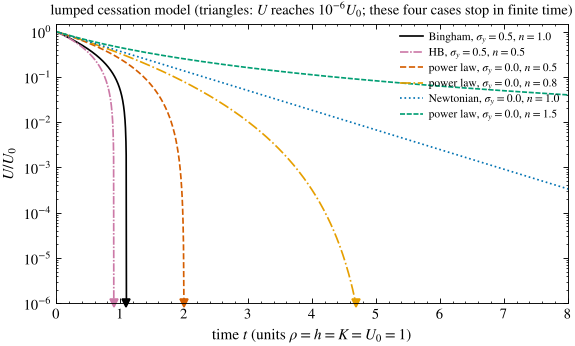

In [10]:
def decay_lumped(ty, n, U0=1.0, t_max=20.0, U_stop=1e-6):
    """rho = h = K = 1. Integrates until U falls to U_stop (the 'displacement resolution' of the record).
    Returns the solution and the time at which U_stop was reached (None if not reached before t_max)."""
    rhs = lambda t, y: [-(ty + max(y[0], 0.0) ** n)]
    stop = lambda t, y: y[0] - U_stop
    stop.terminal = True; stop.direction = -1
    sol = solve_ivp(rhs, (0, t_max), [U0], method="LSODA", rtol=1e-10, atol=1e-13, events=stop, dense_output=True, max_step=0.05)
    t_stop = sol.t_events[0][0] if len(sol.t_events[0]) else None
    return sol, t_stop

def closed_form_time(ty, n, U, U0=1.0):
    """Closed-form time at which U(t) = U in the lumped model (Bingham n = 1, or power law sigma_y = 0, n != 1); rho = h = K = 1."""
    if ty > 0 and n == 1:
        return np.log((U0 + ty) / (U + ty))
    if ty == 0 and n == 1:
        return np.log(U0 / U)
    if ty == 0 and n != 1:
        return (U0 ** (1 - n) - U ** (1 - n)) / (1 - n)
    return None

U_stop = 1e-6
print(f"{'model':38s} {'t(U = 1e-6) num.':>17s} {'closed form':>12s} {'stopping time t_s':>18s}")
cases = [("Bingham, sigma_y = 0.5, n = 1", 0.5, 1.0),
         ("HB, sigma_y = 0.5, n = 0.5", 0.5, 0.5),
         ("power law, sigma_y = 0, n = 0.5", 0.0, 0.5),
         ("power law, sigma_y = 0, n = 0.8", 0.0, 0.8),
         ("Newtonian, sigma_y = 0, n = 1", 0.0, 1.0),
         ("power law, sigma_y = 0, n = 1.5", 0.0, 1.5)]
sols = {}
for name, ty, n in cases:
    sol, t_num = decay_lumped(ty, n, U_stop=U_stop)
    sols[name] = sol
    t_cf = closed_form_time(ty, n, U_stop)
    t_s = closed_form_time(ty, n, 0.0) if (ty > 0 and n == 1) or (ty == 0 and n < 1) else None
    print(f"{name:38s} {'> 20 (not reached)' if t_num is None else f'{t_num:.6f}':>17s} {'' if t_cf is None else f'{t_cf:12.6f}':>12s} "
          f"{'none (U > 0 for all t)' if t_s is None and not (ty > 0) else ('finite' if t_s is None else f'{t_s:.6f}'):>18s}")
    if t_cf is not None and t_num is not None:
        assert np.isclose(t_num, t_cf, rtol=1e-6)
# the HB case with n = 0.5 has no simple closed form: check only that it stops before either term alone would (t = 2)
assert sols["HB, sigma_y = 0.5, n = 0.5"].t_events[0][0] < 2.0

fig, ax = plt.subplots(figsize=(6.0, 3.3))
styles = [(C["black"], "-"), (C["purple"], (0, (5, 1, 1, 1))), (C["red"], "--"), (C["orange"], "-."), (C["blue"], ":"), (C["green"], (0, (3, 1))) ]
for (name, ty, n), (col, ls) in zip(cases, styles):
    sol = sols[name]
    t = np.linspace(0, sol.t[-1], 300)
    label = name.split(",")[0] + rf", $\sigma_y={ty}$, $n={n}$"
    ax.semilogy(t, np.clip(sol.sol(t)[0], 1e-12, None), color=col, ls=ls, label=label)
    if (ty > 0) or n < 1:
        ax.plot(sol.t_events[0][0], U_stop, "v", color=col, ms=5, clip_on=False)
ax.set(xlabel=r"time $t$ (units $\rho=h=K=U_0=1$)", ylabel=r"$U/U_0$", xlim=(0, 8), ylim=(1e-6, 1.5),
       title=r"lumped cessation model (triangles: $U$ reaches $10^{-6}U_0$; these four cases stop in finite time)")
ax.title.set_fontsize(9.5)
ax.legend(fontsize=7.5, loc="upper right")
plt.show()

Four of the six curves stop in finite time: the two with a yield stress **and** the two shear-thinning power-law fluids, which have none. The Newtonian fluid decays exponentially and the shear-thickening fluid ($n=1.5$) even more slowly. With $n=0.8$ the power-law fluid still stops, but later ($t_s=5$ against 2 for $n=0.5$): the closer $n$ is to 1, the longer the finite stopping time, and in an experiment with finite observation time and displacement resolution it becomes indistinguishable from exponential decay — the "operational arrest" of Sec. VII E.

### 6.2 A one-dimensional film without a yield stress — pedagogical illustration

The lumped model assumed a fixed profile shape. We now let the profile evolve: the cessation of a power-law film, $\rho\,\partial_tu=\partial_z\!\left(K|\partial_zu|^{n-1}\partial_zu\right)$ on $0<z<h$ with $u(0,t)=0$ (no slip) and $\partial_zu(h,t)=0$ (stress-free surface), starting from $u(z,0)=U_0\sin(\pi z/2h)$, after the driving force has been switched off. We discretize in $z$ (method of lines, 40 cells) and integrate with `solve_ivp`, stopping when the kinetic energy $E$ falls below $10^{-16}$ of its initial value. If the stop is genuinely in finite time, $E^{(1-n)/2}$ should decrease to zero **linearly** in $t$ near the end, as the equality case of Eq. (S38) predicts; for $n=1$, $\ln E$ decreases linearly instead.

n = 0.5: E below 1e-16 E0 at t = 0.939; E^((1-n)/2) is linear in t and reaches zero at t_s = 0.9387
n = 0.8: E below 1e-16 E0 at t = 2.085; E^((1-n)/2) is linear in t and reaches zero at t_s = 2.1386


n = 1.0: E/E0 = 1.0e-16 at t = 7.5  (exponential decay: 16 decades take 7.5 time units)
n = 1.5: E/E0 = 1.4e-06 at t = 20.0  (algebraic decay, no stop)


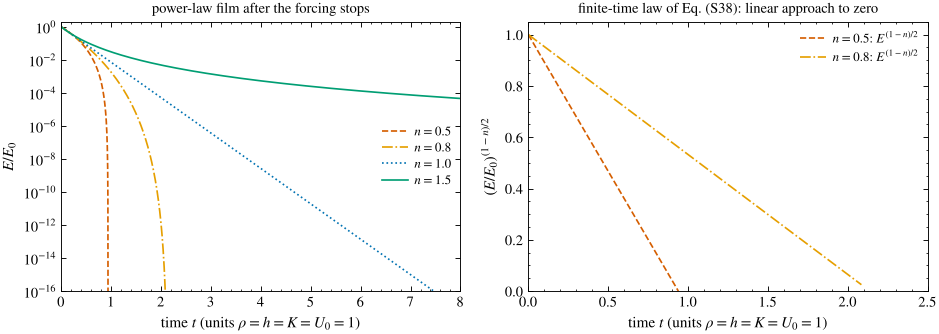

In [11]:
def film_cessation(n, N=40, t_max=20.0):
    """Cessation of a power-law film, rho = K = h = 1, method of lines on N cells; returns (t, E/E0, stop time or None)."""
    z = (np.arange(N) + 0.5) / N
    dz = 1.0 / N
    def rhs(t, u):
        dudz = np.empty(N + 1)
        dudz[0] = u[0] / (dz / 2)              # wall: u = 0 at z = 0
        dudz[1:N] = np.diff(u) / dz
        dudz[N] = 0.0                          # free surface: zero shear stress
        stress = np.sign(dudz) * np.abs(dudz) ** n
        return np.diff(stress) / dz
    u0 = np.sin(np.pi * z / 2)
    E0 = 0.5 * np.mean(u0**2)
    stop = lambda t, u: 0.5 * np.mean(u**2) / E0 - 1e-16
    stop.terminal = True
    sol = solve_ivp(rhs, (0, t_max), u0, method="Radau", rtol=1e-8, atol=1e-14, events=stop, dense_output=True)
    t = np.linspace(0, sol.t[-1], 400)
    E = 0.5 * np.mean(sol.sol(t)**2, axis=0) / E0
    return t, E, (sol.t_events[0][0] if len(sol.t_events[0]) else None)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.8, 3.3))
for n, col, ls in zip([0.5, 0.8, 1.0, 1.5], [C["red"], C["orange"], C["blue"], C["green"]], ["--", "-.", ":", "-"]):
    t, E, t_s = film_cessation(n)
    ax1.semilogy(t, np.clip(E, 1e-17, None), color=col, ls=ls, label=f"$n={n}$")
    if n < 1:
        ax2.plot(t, E ** ((1 - n) / 2), color=col, ls=ls, label=f"$n={n}$: $E^{{(1-n)/2}}$")
        # the (S38)-type linear law near the end: fit the last 30 % of the record and extrapolate to zero
        sel = t > 0.7 * t[-1]
        p = np.polyfit(t[sel], E[sel] ** ((1 - n) / 2), 1)
        t_lin = -p[1] / p[0]
        print(f"n = {n}: E below 1e-16 E0 at t = {t_s:.3f}; E^((1-n)/2) is linear in t and reaches zero at t_s = {t_lin:.4f}")
        assert np.isclose(t_lin, t_s, rtol=0.05) and t_s < t_lin
    else:
        print(f"n = {n}: E/E0 = {E[-1]:.1e} at t = {t[-1]:.1f}" + ("  (exponential decay: 16 decades take 7.5 time units)" if n == 1 else "  (algebraic decay, no stop)"))
ax1.set(xlabel=r"time $t$ (units $\rho=h=K=U_0=1$)", ylabel=r"$E/E_0$", ylim=(1e-16, 2), xlim=(0, 8), title="power-law film after the forcing stops")
ax2.set(xlabel=r"time $t$ (units $\rho=h=K=U_0=1$)", ylabel=r"$(E/E_0)^{(1-n)/2}$", xlim=(0, 2.5), ylim=(0, 1.05),
        title="finite-time law of Eq. (S38): linear approach to zero")
ax1.legend(fontsize=8.5); ax2.legend(fontsize=8.5)
for a in (ax1, ax2): a.title.set_fontsize(9.5)
fig.tight_layout()
plt.show()

The film with $n=0.5$ or $0.8$ loses its kinetic energy in a finite time, and $E^{(1-n)/2}$ approaches zero linearly as in the equality case of Eq. (S38); the Newtonian film ($n=1$) decays exponentially (a straight line on the logarithmic axis) and the shear-thickening film slower still. None of these fluids has a yield stress. In an experiment, the same conclusion holds: a measured finite arrest time is consistent with $\sigma_y>0$ but does not establish it; a yield stress is established by a static test — a stress below which a rested sample does not flow — or by the flow curve itself (notebooks 03 and 09). Note S16 adds two further cautions: regularized creep, continuing boundary work and elastic relaxation change these conclusions, and start-up is not the time reverse of cessation (a thixotropic material may have a larger breakaway stress than its steady fitted intercept; notebook 14).

## 7. Try it yourself

**Exercise 1 — a mud layer on a slope.** A mud with $\sigma_y=40$ Pa, $K=30$ Pa s$^{0.5}$, $n=0.5$, $\rho=1500$ kg/m$^3$ lies on a slope of $5^\circ$. Using Eq. (28): (a) what is the minimum depth $h_c$ for flow? (b) What is the discharge per unit width for $h=2h_c$ and $h=4h_c$, and what fraction of it is carried by the plug? (c) How thick a plug rides on the sheared layer in each case?

*Hint:* $G=\rho g\sin\theta$; the plug contribution is the second term of Eq. (28).

<details><summary>Solution</summary>

```python
ty, K, n, rho_m = 40.0, 30.0, 0.5, 1500.0
G = rho_m * g * np.sin(np.radians(5))
h_c = ty / G
for h in [2 * h_c, 4 * h_c]:
    a = yielded_thickness(G, h, ty)
    q = thin_flux(G, h, ty, K, n)
    q_plug = (G / K) ** (1 / n) * (h - a) * a ** (1 + 1 / n) / (1 + 1 / n)
    print(f"h = {1000*h:.0f} mm: q = {q:.2e} m^2/s, plug share {100*q_plug/q:.0f} %, plug thickness {1000*(h-a):.0f} mm")
# G = 1282 Pa/m, h_c = 31 mm. At h = 2 h_c (62 mm): q = 1.0e-3 m^2/s and the plug carries 57 % of it;
# at h = 4 h_c (125 mm): q = 5.1e-2 m^2/s (fifty times more for twice the depth) and the plug carries 31 %.
# The plug thickness is h - a = sigma_y / G = h_c = 31 mm in both cases: the yielded layer grows, the plug does not.
```
</details>

**Exercise 2 — how precisely must the spread be read?** For the concrete of Sec. 4.2, what relative precision in $R$ is needed for a 10 % relative uncertainty in $\sigma_y$ if $\rho$ and $V$ are exact? And if $V$ is known to 2 %? Check your answer with a Monte Carlo sample.

*Hint:* invert the variance sum of Eq. (S27).

<details><summary>Solution</summary>

```python
target = 0.10
print("R precision with exact rho, V:", target / 5)                       # 2 %
print("R precision with 2 % in V:   ", np.sqrt((target**2 - 4 * 0.02**2) / 25))   # about 1.8 %
rng = np.random.default_rng(1)
s = slump_yield_stress(rho, V * (1 + 0.02 * rng.standard_normal(100000)), 0.35 * (1 + 0.01833 * rng.standard_normal(100000)))
print(s.std() / s.mean())                                                 # about 0.10
# About 2 % in R alone (7 mm on 350 mm), or 1.8 % when V also carries 2 %: the radius must be read to a few millimetres.
```
</details>

**Exercise 3 — a stopping time that looks like a yield stress.** With the lumped model of Sec. 6.1, find the value of $n$ at which a power-law fluid ($\sigma_y=0$, $U_0=1$) stops at the same time as the Bingham fluid with $\sigma_y=0.5$ ($t_s=\ln3\approx1.0986$). Then compute both $U(t)$ curves: could the two be told apart from the velocity record alone?

*Hint:* $t_s=1/(1-n)$ for the power-law fluid with $\rho=h=K=U_0=1$; compare the curvature of $\ln U$ against $t$.

<details><summary>Solution</summary>

```python
n_match = 1 - 1 / np.log(3)                       # about 0.090
sol_b, _ = decay_lumped(0.5, 1.0); sol_p, _ = decay_lumped(0.0, n_match)
t = np.linspace(0, 1.05, 200)
plt.plot(t, sol_b.sol(t)[0], label="Bingham"); plt.plot(t, sol_p.sol(t)[0], "--", label=f"power law n={n_match:.2f}"); plt.xlabel("t"); plt.ylabel("U/U0"); plt.legend(); plt.show()
# n = 0.09: an extremely shear-thinning fluid. The records differ in shape (the power-law curve is almost a straight
# line, very slightly convex; the Bingham curve is strongly convex, an exponential minus a constant),
# but both stop at t = 1.10. The stopping
# time alone does not discriminate; the shape of the decay, the rest state and a static test do.
```
</details>

## Key points

* In a thin layer the shear stress is $G(h-z)$; only a basal layer of thickness $a=(h-\sigma_y/G)_+$ yields, and the rest is a plug (or, where the depth varies, a pseudo-plug). The flux is Eq. (28); it reduces to $Gh^3/(3\mu)$ for a Newtonian film and agrees with a double quadrature of the profile to better than $10^{-8}$.
* Flow needs $Gh>\sigma_y$; near onset $q\propto(G-G_c)^{1+1/n}$. Uniform flow down an incline tests Eq. (28) with no free parameter; a 10–20 % change in $\sigma_y$ and $K$ shifts the predicted height by about 3–14 %.
* An arrested deposit satisfies the inequality $\rho gh|\nabla h|\le\sigma_y$, which admits a family of shapes with the same volume; the slump-flow formula $\sigma_y=225\rho gV^2/(128\pi^2R^5)$ assumes the marginal shape and a shallow layer, and gives 23 Pa (350 mm) and 50 Pa (300 mm) for the worked concrete example.
* Its sensitivity is $\mathrm d\sigma_y/\sigma_y=\mathrm d\rho/\rho+2\,\mathrm dV/V-5\,\mathrm dR/R$: the radius dominates the error budget, and a radius bias propagates as a bias of five times its relative size.
* Spreading drops are governed by $J=\sigma_yR/\Gamma$ and $\mathrm{Bo}=\Delta\rho gR^2/\Gamma$; final radii leave $K$ and $n$ weakly constrained.
* A shear-thinning power-law fluid ($n<1$) also stops in finite time, in a lumped model and in a one-dimensional film; a finite arrest time therefore does not establish $\sigma_y>0$.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* Ancey, C. (2007). Plasticity and geophysical flows: A review. *Journal of Non-Newtonian Fluid Mechanics* **142**, 4–35. https://doi.org/10.1016/j.jnnfm.2006.05.005
* Balmforth, N. J., and Craster, R. V. (1999). A consistent thin-layer theory for Bingham plastics. *Journal of Non-Newtonian Fluid Mechanics* **84**, 65–81. https://doi.org/10.1016/s0377-0257(98)00133-5
* Chambon, G., Ghemmour, A., and Naaim, M. (2014). Experimental investigation of viscoplastic free-surface flows in a steady uniform regime. *Journal of Fluid Mechanics* **754**, 332–364. https://doi.org/10.1017/jfm.2014.378
* Chatzimina, M., Georgiou, G. C., Argyropaidas, I., Mitsoulis, E., and Huilgol, R. R. (2005). Cessation of Couette and Poiseuille flows of a Bingham plastic and finite stopping times. *Journal of Non-Newtonian Fluid Mechanics* **129**, 117–127. https://doi.org/10.1016/j.jnnfm.2005.07.001
* Coussot, P. (1997). *Mudflow Rheology and Dynamics* (Balkema, Rotterdam).
* Huilgol, R. R., Mena, B., and Piau, J. M. (2002). Finite stopping time problems and rheometry of Bingham fluids. *Journal of Non-Newtonian Fluid Mechanics* **102**, 97–107. https://doi.org/10.1016/s0377-0257(01)00166-5
* Jalaal, M., Stoeber, B., and Balmforth, N. J. (2021). Spreading of viscoplastic droplets. *Journal of Fluid Mechanics* **914**, A21. https://doi.org/10.1017/jfm.2020.886
* Pashias, N., Boger, D. V., Summers, J., and Glenister, D. J. (1996). A fifty cent rheometer for yield stress measurement. *Journal of Rheology* **40**, 1179–1189. https://doi.org/10.1122/1.550780
* Roussel, N., and Coussot, P. (2005). "Fifty-cent rheometer" for yield stress measurements: From slump to spreading flow. *Journal of Rheology* **49**, 705–718. https://doi.org/10.1122/1.1879041
* Temam, R., and Strang, G. (1980). Functions of bounded deformation. *Archive for Rational Mechanics and Analysis* **75**, 7–21. https://doi.org/10.1007/bf00284617

### Further reading

* Balmforth, N. J., Frigaard, I. A., and Ovarlez, G. (2014). Yielding to stress: Recent developments in viscoplastic fluid mechanics. *Annual Review of Fluid Mechanics* **46**, 121–146. https://doi.org/10.1146/annurev-fluid-010313-141424
* Coussot, P., and Boyer, S. (1995). Determination of yield stress fluid behaviour from inclined plane test. *Rheologica Acta* **34**, 534–543. https://doi.org/10.1007/bf00712314
* Djaaroun, L., Messelmi, F., Taibi, H., Ramézani, H. A., Meflah, M., Rabehi, A., Agajie, T. F., and Alanazi, A. K. (2025). Numerical investigation of the Herschel–Bulkley fluid flow through thin layers. *AIP Advances* **15**, 115220. https://doi.org/10.1063/5.0298769
* Heitmeier, L., D'Angelo, O., Jalaal, M., and Voigtmann, T. (2026). Spreading droplets of yield-stress fluids with and without gravity. *Journal of Rheology* **70**, 631–643. https://doi.org/10.1122/8.0001083